# LOGO Project — Dataset Audit

Initial dataset exploration and annotation validation.

In [3]:
from pathlib import Path
import xml.etree.ElementTree as ET
import cv2
#import pandas as pd

PROJECT_ROOT = Path(r'E:\Logo_Video_Text_Spotting')
DATASET_ROOT = PROJECT_ROOT / 'datasets'

print('Project root exists:', PROJECT_ROOT.exists())
print('Dataset root exists:', DATASET_ROOT.exists())
print('\nDataset folders:')
for path in sorted(DATASET_ROOT.iterdir()):
    if path.is_dir():
        print(f'{path.name}: {sum(1 for p in path.rglob("*") if p.is_file())} files')

Project root exists: True
Dataset root exists: True

Dataset folders:
DSText: 150 files
ICDAR2013: 56 files
ICDAR2015: 150 files


In [4]:
from collections import Counter

for dataset_name in ["DSText", "ICDAR2013", "ICDAR2015"]:
    dataset_path = DATASET_ROOT / dataset_name

    print(f"\n{'=' * 50}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 50}")

    for folder in sorted(dataset_path.iterdir()):
        if folder.is_dir():
            files = [p for p in folder.rglob("*") if p.is_file()]
            extensions = Counter(
                p.suffix.lower() or "[no extension]" for p in files
            )

            print(f"\nFolder: {folder.name}")
            print(f"Files: {len(files)}")
            print("File types:", dict(extensions))


DATASET: DSText

Folder: test
Files: 50
File types: {'.mp4': 50}

Folder: train
Files: 100
File types: {'.mp4': 50, '.xml': 50}

DATASET: ICDAR2013

Folder: test
Files: 30
File types: {'.mp4': 15, '.xml': 15}

Folder: train
Files: 26
File types: {'.mp4': 13, '.xml': 13}

DATASET: ICDAR2015

Folder: test
Files: 49
File types: {'.txt': 25, '.mp4': 24}

Folder: train
Files: 101
File types: {'.txt': 51, '.mp4': 25, '.xml': 25}


In [5]:
from pathlib import Path

for dataset_name in ["DSText", "ICDAR2013", "ICDAR2015"]:
    dataset_path = DATASET_ROOT / dataset_name

    print(f"\n{'=' * 55}")
    print(f"{dataset_name}: annotation samples")
    print(f"{'=' * 55}")

    for split in ["train", "test"]:
        split_path = dataset_path / split
        annotation_files = sorted(
            p for p in split_path.rglob("*")
            if p.is_file() and p.suffix.lower() in {".xml", ".txt"}
        )

        print(f"\n{split}: {len(annotation_files)} annotation files")

        for path in annotation_files[:2]:
            print(f"\nFile: {path.relative_to(DATASET_ROOT)}")

            if path.suffix.lower() == ".xml":
                print(path.read_text(encoding="utf-8-sig")[:700])
            else:
                with path.open(
                    "r", encoding="utf-8-sig", errors="replace"
                ) as file:
                    print("".join(file.readlines()[:8])[:700])


DSText: annotation samples

train: 50 annotation files

File: DSText\train\Activity\Video_163_6_3_GT.xml
<?xml version="1.0" ?>
<Frames>
  <frame ID="1">
    <object ID="1" Transcription="TONY" category="scene" language="alphanumeric">
      <Point x="524" y="-2"/>
      <Point x="549" y="-2"/>
      <Point x="549" y="169"/>
      <Point x="524" y="169"/>
    </object>
    <object ID="2" Transcription="PARK" category="scene" language="alphanumeric">
      <Point x="708" y="26"/>
      <Point x="740" y="26"/>
      <Point x="740" y="149"/>
      <Point x="708" y="149"/>
    </object>
    <object ID="3" Transcription="PARK" category="scene" language="alphanumeric">
      <Point x="706" y="204"/>
      <Point x="738" y="204"/>
      <Point x="738" y="326"/>
      <Point x="706" y="326"/>
    </obj

File: DSText\train\Activity\Video_170_7_0_GT.xml
<?xml version="1.0" ?>
<Frames>
  <frame ID="1">
    <object ID="1" Transcription="##DONT#CARE##" category="scene" language="alphanumeric">
   

In [6]:
from pathlib import Path

icdar15 = DATASET_ROOT / "ICDAR2015"

for split in ["train", "test"]:
    split_path = icdar15 / split

    print(f"\n{'=' * 55}")
    print(f"ICDAR2015 — {split.upper()}")
    print(f"{'=' * 55}")

    for path in sorted(split_path.glob("*.txt")):
        name = path.name.lower()

        if "vocabulary" in name:
            kind = "VOCABULARY"
        elif "_gt_voc" in name:
            kind = "GROUND-TRUTH VOCABULARY FORMAT"
        elif "_gt" in name:
            kind = "GROUND-TRUTH CANDIDATE"
        else:
            kind = "OTHER — NEEDS INSPECTION"

        print(f"{path.name}: {kind}")

        if kind in {
            "GROUND-TRUTH VOCABULARY FORMAT",
            "GROUND-TRUTH CANDIDATE",
        }:
            with path.open(
                "r", encoding="utf-8-sig", errors="replace"
            ) as file:
                for _, line in zip(range(3), file):
                    print("   ", line.rstrip())


ICDAR2015 — TRAIN
trainsetVocabulary.txt: VOCABULARY
Video_10_1_1_GT.txt: GROUND-TRUTH CANDIDATE
    "218001","cat"
    "247001","Expedicions"
    "107007","transport"
Video_10_1_1_GT_voc.txt: GROUND-TRUTH VOCABULARY FORMAT
    ACCASTILLAGE
    ACCASTILLEUR
    ACCES
Video_13_4_1_GT.txt: GROUND-TRUTH CANDIDATE
    "41001","EXTINTOR"
    "49002","BOCA"
    "56001","PULSADOR"
Video_13_4_1_GT_voc.txt: GROUND-TRUTH VOCABULARY FORMAT
    ABC
    ACCASTILLEUR
    ACCES
Video_16_3_2_GT.txt: GROUND-TRUTH CANDIDATE
    "122001","Coral"
    "91011","azul"
    "88001","ral"
Video_16_3_2_GT_voc.txt: GROUND-TRUTH VOCABULARY FORMAT
    ACCES
    ACO
    ALCAMPO
Video_18_3_1_GT.txt: GROUND-TRUTH CANDIDATE
    "102003","Digestive"
    "127002","Banadas"
    "137006","300g"
Video_18_3_1_GT_voc.txt: GROUND-TRUTH VOCABULARY FORMAT
    ABC
    ACCESSIBILITAT
    ALCAMPO
Video_19_5_1_GT.txt: GROUND-TRUTH CANDIDATE
    "265002","SABADELL"
    "106001","Lietres"
    "215001","BUS"
Video_19_5_1_GT_voc.txt: G

In [7]:
from pathlib import Path

icdar15 = DATASET_ROOT / "ICDAR2015"

for split in ["train", "test"]:
    folder = icdar15 / split

    videos = sorted(folder.glob("*.mp4"))
    regular_gt = sorted(
        p for p in folder.glob("*_GT.txt")
        if not p.name.lower().endswith("_gt_voc.txt")
    )
    vocab_gt = sorted(folder.glob("*_GT_voc.txt"))
    vocabulary_files = [
        p for p in folder.glob("*.txt")
        if "vocabulary" in p.name.lower()
    ]

    video_stems = {p.stem for p in videos}
    gt_stems = {p.name.removesuffix("_GT.txt") for p in regular_gt}

    print(f"\n{'=' * 45}")
    print(f"ICDAR2015 — {split.upper()}")
    print(f"{'=' * 45}")
    print("Videos:", len(videos))
    print("Regular GT files:", len(regular_gt))
    print("Per-video vocabulary files:", len(vocab_gt))
    print("Dataset vocabulary files:", len(vocabulary_files))
    print("Videos without matching regular GT:", len(video_stems - gt_stems))
    print("Regular GT without matching video:", len(gt_stems - video_stems))

    if video_stems - gt_stems:
        print("Examples without GT:", sorted(video_stems - gt_stems)[:5])


ICDAR2015 — TRAIN
Videos: 25
Regular GT files: 25
Per-video vocabulary files: 25
Dataset vocabulary files: 1
Videos without matching regular GT: 0
Regular GT without matching video: 0

ICDAR2015 — TEST
Videos: 24
Regular GT files: 0
Per-video vocabulary files: 24
Dataset vocabulary files: 1
Videos without matching regular GT: 24
Regular GT without matching video: 0
Examples without GT: ['Video_11_4_1', 'Video_15_4_1', 'Video_17_3_1', 'Video_1_1_2', 'Video_20_5_1']


Video: Video_10_1_1.mp4
Resolution: 1280 × 960
FPS: 24.0
Frame count: 336
Duration (seconds): 14.0


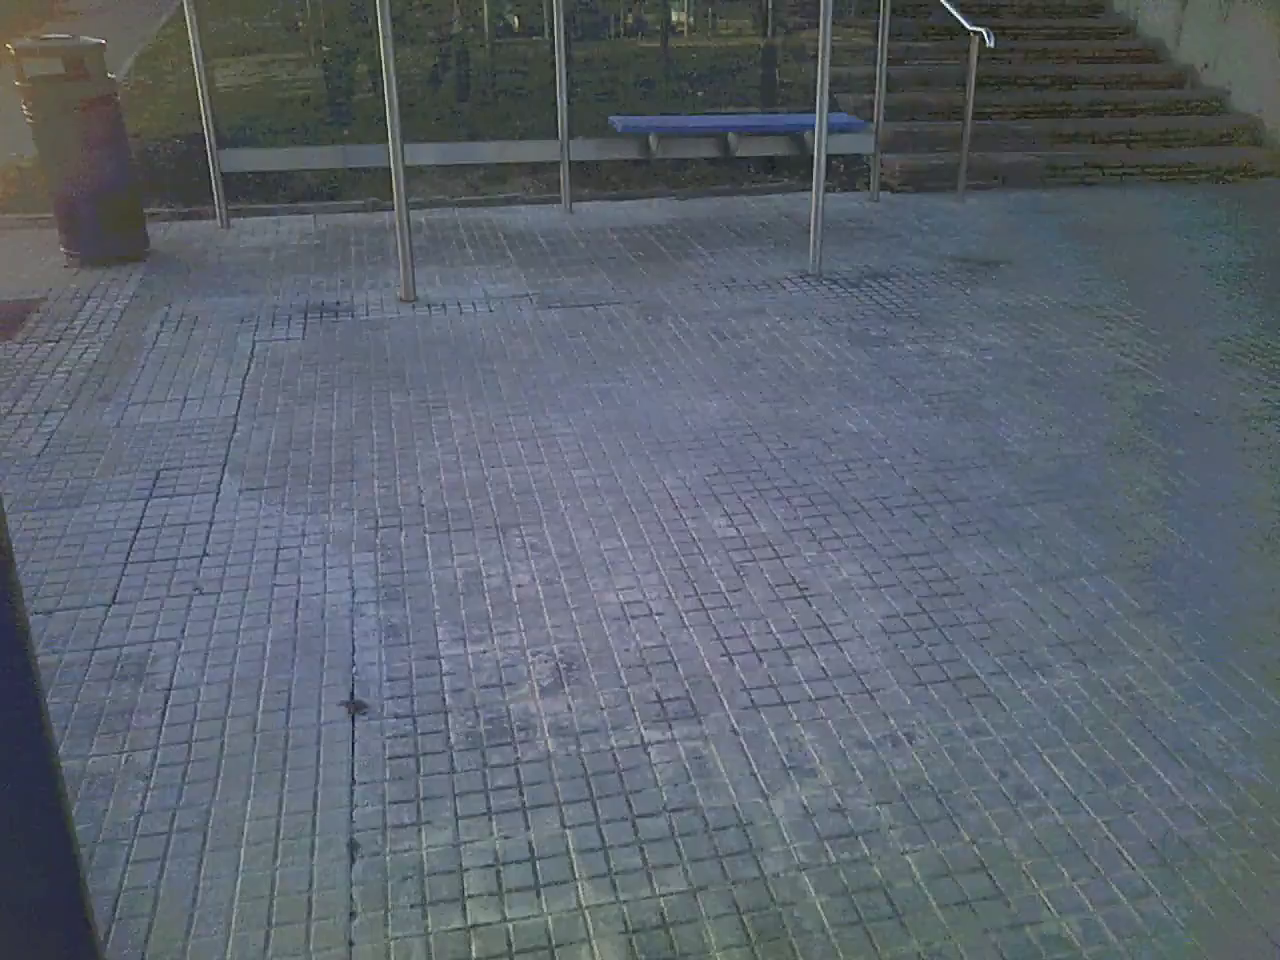

In [8]:
import cv2
from pathlib import Path
from IPython.display import display, Image

video_path = (
    DATASET_ROOT
    / "ICDAR2015"
    / "train"
    / "Video_10_1_1.mp4"
)

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    print("ERROR: Could not open video:", video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    print("Video:", video_path.name)
    print("Resolution:", f"{width} × {height}")
    print("FPS:", fps)
    print("Frame count:", frame_count)
    print("Duration (seconds):", round(frame_count / fps, 2) if fps > 0 else "Unknown")

    success, frame = cap.read()
    if success:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        display(Image(data=cv2.imencode(".png", cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR))[1].tobytes()))

    cap.release()

In [9]:
import xml.etree.ElementTree as ET
import cv2
import matplotlib.pyplot as plt

# Select the ICDAR2015 training video and its XML annotations
video_path = DATASET_ROOT / "ICDAR2015" / "train" / "Video_10_1_1.mp4"
xml_path = DATASET_ROOT / "ICDAR2015" / "train" / "Video_10_1_1_GT.xml"

# Read the XML structure
root = ET.parse(xml_path).getroot()

# Inspect the first few frame IDs and object counts
for frame_element in root.findall("frame")[:10]:
    objects = frame_element.findall("object")
    print(
        "Frame ID:", frame_element.get("ID"),
        "| Objects:", len(objects)
    )

Frame ID: 1 | Objects: 0
Frame ID: 2 | Objects: 0
Frame ID: 3 | Objects: 0
Frame ID: 4 | Objects: 0
Frame ID: 5 | Objects: 0
Frame ID: 6 | Objects: 0
Frame ID: 7 | Objects: 0
Frame ID: 8 | Objects: 1
Frame ID: 9 | Objects: 1
Frame ID: 10 | Objects: 1


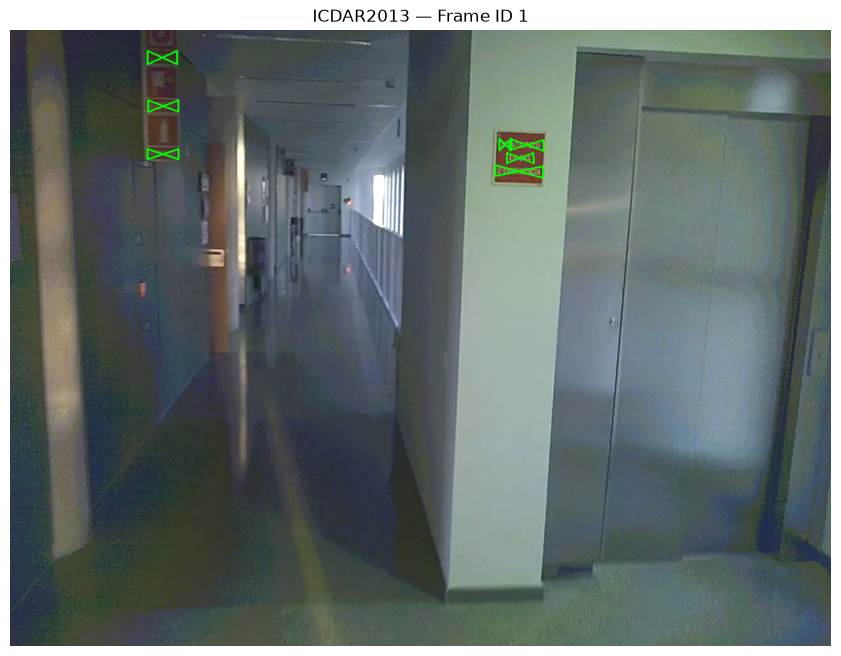

In [10]:
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

video_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1.mp4"
xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"

root = ET.parse(xml_path).getroot()
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    print("Could not open video:", video_path)
else:
    selected_frame = None

    for frame_element in root.findall("frame"):
        objects = frame_element.findall("object")
        if objects:
            frame_id = int(frame_element.get("ID"))
            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id - 1)
            ok, frame = cap.read()

            if ok:
                selected_frame = frame
                break

    if selected_frame is None:
        print("No annotated frame could be read.")
    else:
        for obj in objects:
            points = [
                (int(float(p.get("x"))), int(float(p.get("y"))))
                for p in obj.findall("Point")
            ]

            if len(points) >= 3:
                polygon = __import__("numpy").array(points, dtype="int32")
                cv2.polylines(
                    selected_frame, [polygon], True, (0, 255, 0), 2
                )

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(selected_frame, cv2.COLOR_BGR2RGB))
        plt.title(f"ICDAR2013 — Frame ID {frame_id}")
        plt.axis("off")
        plt.show()

    cap.release()

In [11]:
import xml.etree.ElementTree as ET

xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"
root = ET.parse(xml_path).getroot()

frame = next(
    f for f in root.findall("frame")
    if f.get("ID") == "1" and f.findall("object")
)

print("Frame ID:", frame.get("ID"))

for i, obj in enumerate(frame.findall("object")[:5], start=1):
    print(f"\nObject {i}")
    print("Text:", obj.get("Transcription"))
    print("Object attributes:", obj.attrib)

    points = [
        (p.get("x"), p.get("y"))
        for p in obj.findall("Point")
    ]
    print("Raw points:", points)

Frame ID: 1

Object 1
Text: NO
Object attributes: {'Transcription': 'NO', 'ID': '1001', 'Language': 'Catalan', 'Mirrored': 'Unmirrored', 'Quality': 'MODERATE'}
Raw points: [('762', '169'), ('762', '187'), ('781', '169'), ('781', '187')]

Object 2
Text: #Don't care#
Object attributes: {'Transcription': "#Don't care#", 'ID': '1002', 'Language': 'Catalan', 'Mirrored': 'Unmirrored', 'Quality': 'LOW'}
Raw points: [('831', '188'), ('831', '171'), ('778', '187'), ('779', '169')]

Object 3
Text: ENCAS
Object attributes: {'Transcription': 'ENCAS', 'ID': '1003', 'Language': 'Catalan', 'Mirrored': 'Unmirrored', 'Quality': 'MODERATE'}
Raw points: [('774', '191'), ('774', '207'), ('815', '191'), ('816', '207')]

Object 4
Text: #Don't care#
Object attributes: {'Transcription': "#Don't care#", 'ID': '1004', 'Language': 'Catalan', 'Mirrored': 'Unmirrored', 'Quality': 'LOW'}
Raw points: [('756', '210'), ('756', '227'), ('830', '212'), ('830', '230')]

Object 5
Text: #Don't care#
Object attributes: {'Tr

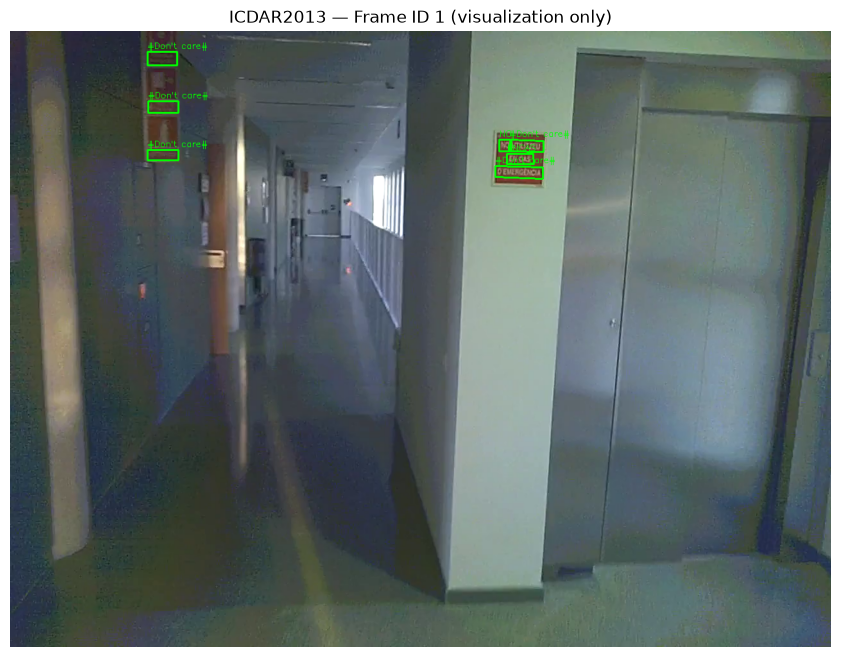

In [25]:
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

video_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1.mp4"
xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"

root = ET.parse(xml_path).getroot()
frame_element = next(
    f for f in root.findall("frame")
    if f.get("ID") == "1" and f.findall("object")
)

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame = cap.read()
cap.release()

if not ok:
    print("Could not read the video frame.")
else:
    for obj in frame_element.findall("object"):
        points = np.array([
            [float(p.get("x")), float(p.get("y"))]
            for p in obj.findall("Point")
        ], dtype=np.float32)

        if len(points) < 3:
            continue

        # Sort points by angle around their center for visualization only.
        center = points.mean(axis=0)
        angles = np.arctan2(
            points[:, 1] - center[1],
            points[:, 0] - center[0]
        )
        polygon = points[np.argsort(angles)].astype(np.int32)

        cv2.polylines(frame, [polygon], True, (0, 255, 0), 2)

        x, y = polygon.min(axis=0)
        text = obj.get("Transcription", "")
        cv2.putText(
            frame, text, (int(x), max(15, int(y) - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1
        )

    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("ICDAR2013 — Frame ID 1 (visualization only)")
    plt.axis("off")
    plt.show()

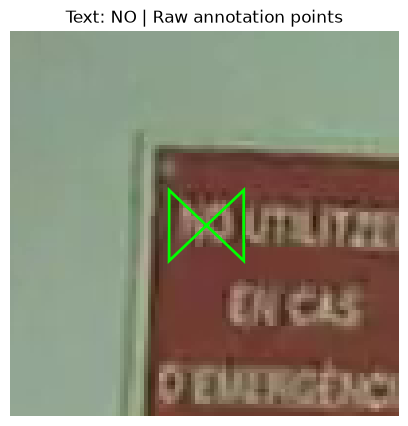

In [13]:
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from matplotlib.patches import Polygon

video_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1.mp4"
xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"

root = ET.parse(xml_path).getroot()
frame_element = next(
    f for f in root.findall("frame")
    if f.get("ID") == "1" and f.findall("object")
)

obj = frame_element.findall("object")[0]
points = [
    (float(p.get("x")), float(p.get("y")))
    for p in obj.findall("Point")
]

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame = cap.read()
cap.release()

if ok:
    x_coords = [p[0] for p in points]
    y_coords = [p[1] for p in points]

    pad = 40
    x1 = max(0, int(min(x_coords)) - pad)
    x2 = min(frame.shape[1], int(max(x_coords)) + pad)
    y1 = max(0, int(min(y_coords)) - pad)
    y2 = min(frame.shape[0], int(max(y_coords)) + pad)

    crop = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(crop)
    ax.add_patch(
        Polygon(
            [(x - x1, y - y1) for x, y in points],
            closed=True,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )
    )
    ax.set_title(f"Text: {obj.get('Transcription')} | Raw annotation points")
    ax.axis("off")
    plt.show()
else:
    print("Could not read the video frame.")

In [14]:
import xml.etree.ElementTree as ET
from collections import Counter

xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"
root = ET.parse(xml_path).getroot()

point_patterns = Counter()
total_objects = 0

for frame in root.findall("frame"):
    for obj in frame.findall("object"):
        points = [
            (float(p.get("x")), float(p.get("y")))
            for p in obj.findall("Point")
        ]

        if len(points) == 4:
            total_objects += 1

            # Record whether the first two points share x or y coordinates.
            if points[0][0] == points[1][0]:
                point_patterns["first pair shares x"] += 1
            elif points[0][1] == points[1][1]:
                point_patterns["first pair shares y"] += 1
            else:
                point_patterns["first pair shares neither"] += 1
        else:
            point_patterns[f"not 4 points ({len(points)})"] += 1

print("Four-point objects:", total_objects)
print("Point-order patterns:")
for pattern, count in point_patterns.items():
    print(f"  {pattern}: {count}")

Four-point objects: 1635
Point-order patterns:
  first pair shares x: 724
  first pair shares neither: 826
  first pair shares y: 85


In [15]:
import xml.etree.ElementTree as ET
import numpy as np

xml_path = DATASET_ROOT / "ICDAR2013" / "train" / "Video_13_4_1_GT.xml"
root = ET.parse(xml_path).getroot()

areas = []
zero_width = 0
zero_height = 0
non_four_points = 0

for frame in root.findall("frame"):
    for obj in frame.findall("object"):
        points = [
            (float(p.get("x")), float(p.get("y")))
            for p in obj.findall("Point")
        ]

        if len(points) != 4:
            non_four_points += 1
            continue

        points = np.asarray(points)
        width = points[:, 0].max() - points[:, 0].min()
        height = points[:, 1].max() - points[:, 1].min()

        if width == 0:
            zero_width += 1
        if height == 0:
            zero_height += 1

        areas.append(width * height)

print("Four-point objects:", len(areas))
print("Zero-width boxes:", zero_width)
print("Zero-height boxes:", zero_height)

if areas:
    print("Bounding-box area percentiles:")
    for percentile in [0, 25, 50, 75, 95, 100]:
        print(f"  {percentile}%: {np.percentile(areas, percentile):.1f}")

Four-point objects: 1635
Zero-width boxes: 0
Zero-height boxes: 0
Bounding-box area percentiles:
  0%: 56.0
  25%: 407.0
  50%: 924.0
  75%: 2080.0
  95%: 6633.9
  100%: 19856.0


In [16]:
import xml.etree.ElementTree as ET

dataset = DATASET_ROOT / "ICDAR2013" / "train"
xml_files = sorted(dataset.glob("*_GT.xml"))

print("Video annotation structure\n")

for xml_path in xml_files[:5]:
    root = ET.parse(xml_path).getroot()
    frames = root.findall("frame")
    objects = [obj for frame in frames for obj in frame.findall("object")]

    point_counts = {}
    for obj in objects:
        count = len(obj.findall("Point"))
        point_counts[count] = point_counts.get(count, 0) + 1

    print(xml_path.name)
    print("  Frames:", len(frames))
    print("  Objects:", len(objects))
    print("  Points per object:", point_counts)
    print("  First object text:",
          objects[0].get("Transcription") if objects else "(no objects)")

Video annotation structure

Video_13_4_1_GT.xml
  Frames: 576
  Objects: 1635
  Points per object: {4: 1635}
  First object text: NO
Video_19_5_1_GT.xml
  Frames: 408
  Objects: 2509
  Points per object: {4: 2509}
  First object text: 0
Video_26_5_2_GT.xml
  Frames: 387
  Objects: 1356
  Points per object: {4: 1356}
  First object text: 555
Video_36_2_3_GT.xml
  Frames: 336
  Objects: 2133
  Points per object: {4: 2133}
  First object text: RECEPTION
Video_37_2_3_GT.xml
  Frames: 456
  Objects: 4530
  Points per object: {4: 4530}
  First object text: JEANNEAU


In [17]:
import xml.etree.ElementTree as ET

dataset = DATASET_ROOT / "DSText" / "train"
xml_files = sorted(dataset.rglob("*_GT.xml"))

print("DSText annotation structure\n")

for xml_path in xml_files[:5]:
    root = ET.parse(xml_path).getroot()
    frames = root.findall("frame")
    objects = [obj for frame in frames for obj in frame.findall("object")]

    point_counts = {}
    categories = {}
    languages = {}

    for obj in objects:
        count = len(obj.findall("Point"))
        point_counts[count] = point_counts.get(count, 0) + 1

        category = obj.get("category", "(missing)")
        language = obj.get("language", "(missing)")
        categories[category] = categories.get(category, 0) + 1
        languages[language] = languages.get(language, 0) + 1

    print(xml_path.relative_to(dataset))
    print("  Frames:", len(frames))
    print("  Text objects:", len(objects))
    print("  Points per object:", point_counts)
    print("  Categories:", categories)
    print("  Languages:", languages)
    print("  First object text:",
          objects[0].get("Transcription") if objects else "(no objects)")

DSText annotation structure

Activity\Video_163_6_3_GT.xml
  Frames: 449
  Text objects: 13820
  Points per object: {4: 13820}
  Categories: {'scene': 13820}
  Languages: {'alphanumeric': 13820}
  First object text: TONY
Activity\Video_170_7_0_GT.xml
  Frames: 147
  Text objects: 20646
  Points per object: {4: 20646}
  Categories: {'scene': 20646}
  Languages: {'alphanumeric': 20646}
  First object text: ##DONT#CARE##
Activity\Video_176_7_6_GT.xml
  Frames: 299
  Text objects: 8451
  Points per object: {4: 8451}
  Categories: {'scene': 8451}
  Languages: {'alphanumeric': 8451}
  First object text: tv
Activity\Video_177_7_7_GT.xml
  Frames: 291
  Text objects: 25511
  Points per object: {4: 25511}
  Categories: {'scene': 25511}
  Languages: {'alphanumeric': 25511}
  First object text: TEXTURE 
Activity\Video_179_7_9_GT.xml
  Frames: 147
  Text objects: 13229
  Points per object: {4: 13229}
  Categories: {'scene': 13229}
  Languages: {'alphanumeric': 13229}
  First object text: 24


In [18]:
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

dataset = DATASET_ROOT / "DSText" / "train"
xml_files = sorted(dataset.rglob("*_GT.xml"))

total_frames = 0
total_objects = 0
point_counts = Counter()
categories = Counter()
languages = Counter()
special_texts = Counter()
missing_transcriptions = 0

for xml_path in xml_files:
    root = ET.parse(xml_path).getroot()
    frames = root.findall("frame")
    total_frames += len(frames)

    for frame in frames:
        for obj in frame.findall("object"):
            total_objects += 1

            point_counts[len(obj.findall("Point"))] += 1
            categories[obj.get("category", "(missing)")] += 1
            languages[obj.get("language", "(missing)")] += 1

            text = obj.get("Transcription", "")
            if not text.strip():
                missing_transcriptions += 1

            if "DONT#CARE" in text.upper():
                special_texts[text] += 1

print("DSText TRAIN — FULL ANNOTATION SUMMARY")
print("XML files:", len(xml_files))
print("Frames:", total_frames)
print("Text objects:", total_objects)
print("Points per object:", dict(point_counts))
print("Categories:", dict(categories))
print("Languages:", dict(languages))
print("Missing/blank transcriptions:", missing_transcriptions)
print("Special transcription variants:", dict(special_texts))

DSText TRAIN — FULL ANNOTATION SUMMARY
XML files: 50
Frames: 12103
Text objects: 945959
Points per object: {4: 945959}
Categories: {'scene': 945959}
Languages: {'alphanumeric': 945959}
Missing/blank transcriptions: 146
Special transcription variants: {'##DONT#CARE##': 160987}


In [19]:
import xml.etree.ElementTree as ET

dataset = DATASET_ROOT / "DSText" / "train"
shown = 0

for xml_path in sorted(dataset.rglob("*_GT.xml")):
    root = ET.parse(xml_path).getroot()

    for frame in root.findall("frame"):
        for obj in frame.findall("object"):
            text = obj.get("Transcription", "")

            if not text.strip():
                points = [
                    (p.get("x"), p.get("y"))
                    for p in obj.findall("Point")
                ]

                print({
                    "file": xml_path.name,
                    "frame_id": frame.get("ID"),
                    "object_id": obj.get("ID"),
                    "transcription": repr(text),
                    "points": points,
                })

                shown += 1
                if shown >= 20:
                    break

        if shown >= 20:
            break

    if shown >= 20:
        break

print(f"\nDisplayed {shown} examples.")

{'file': 'Video_234_3_4_GT.xml', 'frame_id': '48', 'object_id': '9', 'transcription': "' '", 'points': [('-2', '359'), ('0', '348'), ('15', '351'), ('13', '362')]}
{'file': 'Video_104_0_4_GT.xml', 'frame_id': '138', 'object_id': '255', 'transcription': "' '", 'points': [('180', '739'), ('236', '739'), ('236', '753'), ('180', '753')]}
{'file': 'Video_104_0_4_GT.xml', 'frame_id': '139', 'object_id': '255', 'transcription': "' '", 'points': [('180', '739'), ('236', '739'), ('236', '753'), ('180', '753')]}
{'file': 'Video_104_0_4_GT.xml', 'frame_id': '140', 'object_id': '255', 'transcription': "' '", 'points': [('180', '739'), ('236', '739'), ('236', '753'), ('180', '753')]}
{'file': 'Video_104_0_4_GT.xml', 'frame_id': '141', 'object_id': '255', 'transcription': "' '", 'points': [('180', '739'), ('236', '739'), ('236', '753'), ('180', '753')]}
{'file': 'Video_104_0_4_GT.xml', 'frame_id': '142', 'object_id': '255', 'transcription': "' '", 'points': [('177', '741'), ('233', '741'), ('233', '

In [20]:
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict

dataset = DATASET_ROOT / "DSText" / "train"

text_types = Counter()
examples_by_type = defaultdict(list)

for xml_path in sorted(dataset.rglob("*_GT.xml")):
    root = ET.parse(xml_path).getroot()

    for frame in root.findall("frame"):
        for obj in frame.findall("object"):
            text = obj.get("Transcription", "")

            if not text.strip():
                kind = repr(text)
                text_types[kind] += 1

                if len(examples_by_type[kind]) < 3:
                    examples_by_type[kind].append(
                        (xml_path.name, frame.get("ID"), obj.get("ID"))
                    )

print("Whitespace/blank transcription variants:")
for kind, count in text_types.items():
    print(f"\n{kind}: {count} objects")
    print("Examples:", examples_by_type[kind])

print("\nTotal whitespace/blank objects:", sum(text_types.values()))

Whitespace/blank transcription variants:

' ': 146 objects
Examples: [('Video_234_3_4_GT.xml', '48', '9'), ('Video_104_0_4_GT.xml', '138', '255'), ('Video_104_0_4_GT.xml', '139', '255')]

Total whitespace/blank objects: 146


Target transcription: ' '
Target points: [(-2, 359), (0, 348), (15, 351), (13, 362)]


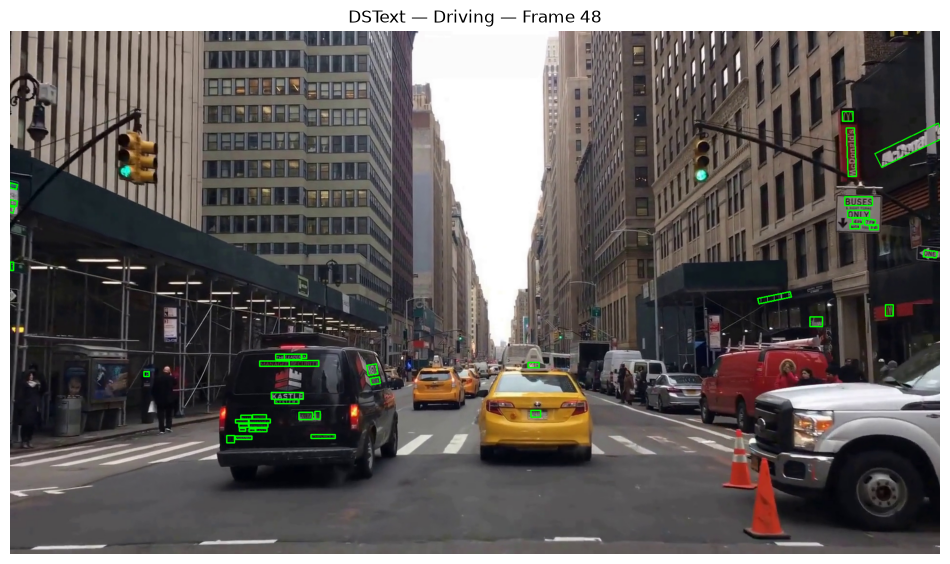

In [21]:
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

video_path = DATASET_ROOT / "DSText" / "train" / "Driving" / "Video_234_3_4.mp4"
xml_path = DATASET_ROOT / "DSText" / "train" / "Driving" / "Video_234_3_4_GT.xml"

root = ET.parse(xml_path).getroot()
frame_element = next(
    f for f in root.findall("frame") if f.get("ID") == "48"
)

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, 47)
ok, frame = cap.read()
cap.release()

if not ok:
    print("Could not read video frame 48.")
else:
    target = None

    for obj in frame_element.findall("object"):
        points = [
            (int(float(p.get("x"))), int(float(p.get("y"))))
            for p in obj.findall("Point")
        ]

        if len(points) >= 3:
            for i in range(len(points)):
                cv2.line(
                    frame, points[i], points[(i + 1) % len(points)],
                    (0, 255, 0), 2
                )

        if obj.get("ID") == "9":
            target = obj
            print("Target transcription:", repr(obj.get("Transcription")))
            print("Target points:", points)

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("DSText — Driving — Frame 48")
    plt.axis("off")
    plt.show()

Transcription: ' '
Coordinates: [(-2.0, 359.0), (0.0, 348.0), (15.0, 351.0), (13.0, 362.0)]


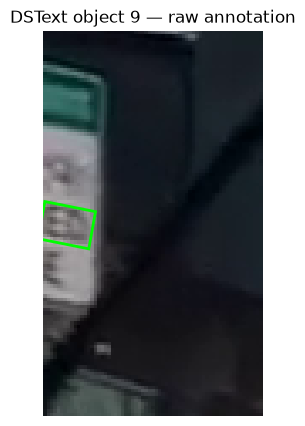

In [22]:
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

video_path = DATASET_ROOT / "DSText" / "train" / "Driving" / "Video_234_3_4.mp4"
xml_path = DATASET_ROOT / "DSText" / "train" / "Driving" / "Video_234_3_4_GT.xml"

root = ET.parse(xml_path).getroot()
frame_element = next(
    f for f in root.findall("frame") if f.get("ID") == "48"
)

target = next(
    obj for obj in frame_element.findall("object")
    if obj.get("ID") == "9"
)

points = [
    (float(p.get("x")), float(p.get("y")))
    for p in target.findall("Point")
]

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, 47)
ok, frame = cap.read()
cap.release()

print("Transcription:", repr(target.get("Transcription")))
print("Coordinates:", points)

if ok:
    h, w = frame.shape[:2]
    pad = 50

    x1 = max(0, int(min(x for x, y in points)) - pad)
    y1 = max(0, int(min(y for x, y in points)) - pad)
    x2 = min(w, int(max(x for x, y in points)) + pad)
    y2 = min(h, int(max(y for x, y in points)) + pad)

    crop = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(crop)
    ax.add_patch(Polygon(
        [(x - x1, y - y1) for x, y in points],
        closed=True, fill=False, edgecolor="lime", linewidth=2
    ))
    ax.set_title("DSText object 9 — raw annotation")
    ax.axis("off")
    plt.show()

In [23]:
from pathlib import Path
from datetime import date

PROJECT_ROOT = Path(r"E:\Logo_Video_Text_Spotting")
LOG_DIR = PROJECT_ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

summary = """
LOGO PROJECT — DATASET AUDIT CHECKPOINT
=======================================

Status: DONE FOR TODAY
Date: {date}

DATASET INVENTORY
-----------------
DSText:
- Train: 50 videos, 50 XML files
- Test: 50 videos, no local annotation files found

ICDAR2013:
- Train: 13 videos, 13 XML files
- Test: 15 videos, 15 XML files

ICDAR2015:
- Train: 25 videos, 25 regular GT TXT files,
  25 per-video vocabulary files
- Test: 24 videos, no regular GT TXT files found,
  24 per-video vocabulary files

DSTEXT TRAIN ANNOTATION AUDIT
-----------------------------
- XML files: 50
- Frames: 12,103
- Text objects: 945,959
- Four-point objects: 945,959
- Blank/whitespace transcriptions: 146
- ##DONT#CARE## annotations: 160,987
- XML read errors: 0

VISUAL INSPECTION
-----------------
- Successfully opened sample videos and displayed frames.
- Inspected XML annotation coordinates.
- Tested polygon overlays and zoomed annotation crops.
- Polygon point ordering requires further validation.
- Original annotations have not been modified.

OPEN ISSUES
-----------
1. Locate or verify official DSText test ground truth.
2. Locate or verify regular ICDAR2015 test ground truth.
3. Investigate the 146 whitespace transcriptions.
4. Confirm annotation geometry and frame alignment.
5. Check official LOGO implementation and dependencies
   before beginning baseline reproduction.

NEXT SESSION
------------
Resume with dataset audit documentation and remaining
ground-truth checks. Then prepare a reproducible dataset
reader and validate annotations before model training.

No model training has started.
""".format(date=date.today().isoformat())

checkpoint = LOG_DIR / "dataset_audit_summary.txt"
checkpoint.write_text(summary.strip() + "\n", encoding="utf-8")

print(summary)
print(f"\nCheckpoint saved to: {checkpoint}")
print("\nDONE FOR TODAY — dataset audit checkpoint created.")


LOGO PROJECT — DATASET AUDIT CHECKPOINT

Status: DONE FOR TODAY
Date: 2026-10-16

DATASET INVENTORY
-----------------
DSText:
- Train: 50 videos, 50 XML files
- Test: 50 videos, no local annotation files found

ICDAR2013:
- Train: 13 videos, 13 XML files
- Test: 15 videos, 15 XML files

ICDAR2015:
- Train: 25 videos, 25 regular GT TXT files,
  25 per-video vocabulary files
- Test: 24 videos, no regular GT TXT files found,
  24 per-video vocabulary files

DSTEXT TRAIN ANNOTATION AUDIT
-----------------------------
- XML files: 50
- Frames: 12,103
- Text objects: 945,959
- Four-point objects: 945,959
- Blank/whitespace transcriptions: 146
- ##DONT#CARE## annotations: 160,987
- XML read errors: 0

VISUAL INSPECTION
-----------------
- Successfully opened sample videos and displayed frames.
- Inspected XML annotation coordinates.
- Tested polygon overlays and zoomed annotation crops.
- Polygon point ordering requires further validation.
- Original annotations have not been modified.

OPEN